In [1]:
%pip install keras
%pip install tensorflow
%pip install numpy
%pip install scikit-learn
%pip install pandas



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [126]:
from keras.models import Sequential
from keras.layers import Conv2D
from keras.layers import MaxPooling2D
from keras.layers import GlobalMaxPooling2D
from keras.layers import Dense
from keras.layers import Flatten
from keras.layers import Dropout
from matplotlib import pyplot
from keras.layers import BatchNormalization
import numpy as np
from keras.utils import to_categorical
import matplotlib.pyplot as plt
from keras.datasets import cifar10
from keras import optimizers
import tensorflow as tf
from keras.src.legacy.preprocessing.image import ImageDataGenerator



Downloading the CIFAR10 dataset: contains 60,000 color images in 10 classes, with 6,000 images in each class. The dataset is divided into 50,000 training images and 10,000 testing images.

In [188]:
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()


In [189]:
print(train_labels.shape)

(50000, 1)


Verify the data by plotting the first 25 images and dispalying the classes of the images:

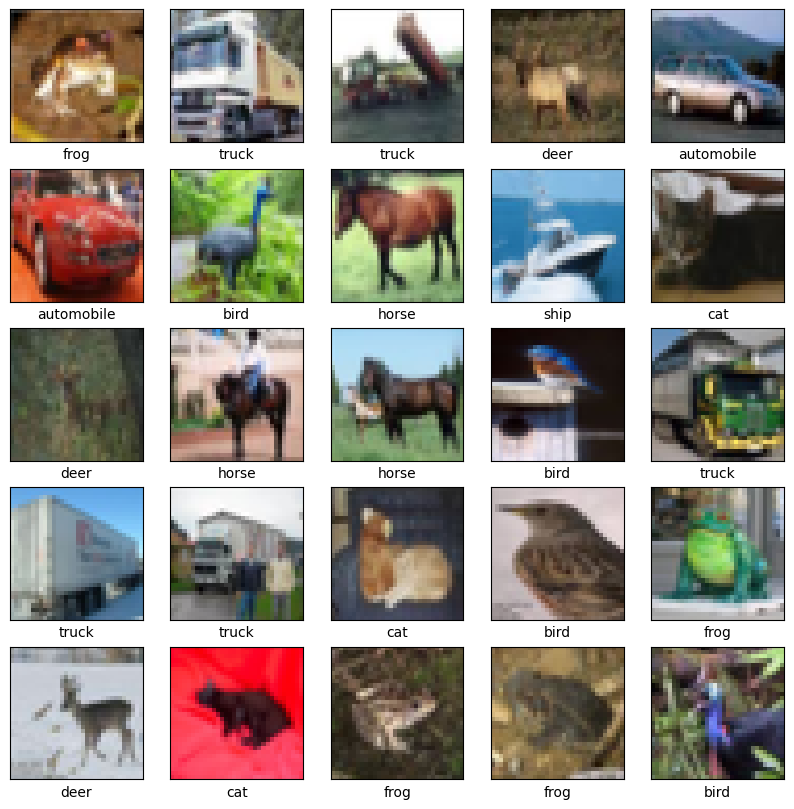

In [190]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays, 
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()

In [191]:
# Convert class vectors to binary class matrices using one hot encoding
train_y = to_categorical(train_labels, num_classes = 10)
test_y = to_categorical(test_labels, num_classes = 10)

print(train_y.shape)
print(test_y.shape)

(50000, 10)
(10000, 10)


In [192]:
# Data normalization
train_images = train_images.astype('float32')
test_images = test_images.astype('float32')
train_images  /= 255
test_images /= 255

print("******************")
print(train_images.shape)
print(test_images.shape)

******************
(50000, 32, 32, 3)
(10000, 32, 32, 3)


In [ ]:
Creating the convolutional base using common stack pattern: Conv2D and MaxPooling2D layers.

Input in CNN is taken in the shape of image_height, image_width and color_channels (R,G,B) - in this example we need to process input in the shape of (32, 32, 3) 
as this is the shape of CIFAR10 images. 

Adding the dense layers for the classification: the last convolutinal layer of the shape of 4, 4, 64 will be fed into the dense layer. 

Because the dense layers take input as 1D vectors and current input is a 3D tensor - this needs to be flattened. 
After this a dense layer is added and another dense layer with 10 outputs for the 10 classes of the images.

In [ ]:
Baseline Model

In [157]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax', name='predictions'))

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

Model 1 - inspired by the VGG network built of two blocks of convolutional and pooling layers:

In [17]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', input_shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Flatten())
model.add(Dense(64, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax', name='predictions'))

In [18]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,682 (658.91 KB)

 Trainable params: 168,682 (658.91 KB)

 Non-trainable params: 0 (0.00 B)

Model 2 - inspired by VGG model of 3 blocks:

In [182]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', input_shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Flatten())
model.add(Dense(64, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax', name='predictions'))

In [35]:
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_19 (Conv2D)              │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_22 (Conv2D)              │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_23 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 1, 1, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,914 (1.13 MB)

 Trainable params: 295,914 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

Model 3 - adding the drouput regularazation

In [139]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform', input_shape=(32, 32, 3)))
model.add(Conv2D(32, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(MaxPooling2D((2, 2)))
model.add(Dropout(0.2))
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Conv2D(128, (3, 3), activation='relu', kernel_initializer='he_uniform'))
model.add(Flatten())
model.add(Dense(64, activation='relu', kernel_initializer='he_uniform'))
model.add(Dense(10, activation='softmax', name='predictions'))

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model 4 - Kernel Reguliser

In [193]:
model = Sequential()
model.add(Conv2D(32, (3, 3), activation='relu', kernel_regularizer="l2", input_shape=(32, 32, 3)))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_regularizer="l2",))
model.add(MaxPooling2D((2, 2)))
model.add(Conv2D(64, (3, 3), activation='relu', kernel_regularizer="l2",))
model.add(Flatten())
model.add(Dense(64, activation='relu'))
model.add(Dense(10, activation='softmax', name='predictions'))

/Library/Frameworks/Python.framework/Versions/3.10/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [132]:
import tensorflow as tf
tf.compat.v1.enable_eager_execution()
import math

In [133]:
print("Eager Execution Enabled:", tf.executing_eagerly())

Eager Execution Enabled: True


Model 5 - Data augementation. 

The CIFAR dataset consists of very small images of objects, we don't want too much destortion. To preserve useful features, only some basic augmentation will be implemented: horizpntal flip, and width and height shift of 10%. 

In [164]:
# Constants
IMG_SIZE = 32  # Adjust the image size as needed

# Resize and rescale function with augmentation
def resize_and_augment(image, label):
    # Resize the image to the target size
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    
    # Normalize pixel values to [0, 1]
    image = image / 255.0
    
    # Augmentation: Apply width shift, height shift, and horizontal flip
    # Randomly shift the image horizontally and vertically
    image = tf.image.random_flip_left_right(image)  # Horizontal flip
    image = tf.image.random_flip_up_down(image)    # Vertical flip (optional)
    image = tf.image.random_crop(image, size=[IMG_SIZE, IMG_SIZE, 3])  # Random crop
    
    # Optionally: apply width and height shift
    image = tf.image.random_flip_left_right(image)  # Random horizontal flip
    image = tf.image.random_flip_up_down(image)    # Random vertical flip
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE + 4, IMG_SIZE + 4) # Random padding
    image = tf.image.random_crop(image, size=[IMG_SIZE, IMG_SIZE, 3])  # Random crop back to the desired size

    return image, label


# Create a tf.data.Dataset from your images and labels
train_dataset = tf.data.Dataset.from_tensor_slices((train_images, train_y))
test_dataset = tf.data.Dataset.from_tensor_slices((test_images, test_y))

# Apply resize, augmentations, and batching to the training dataset
train_dataset = train_dataset.map(resize_and_augment, num_parallel_calls=tf.data.AUTOTUNE)
train_dataset = train_dataset.batch(64).shuffle(1000).prefetch(tf.data.AUTOTUNE)

# Apply resize to test data, no augmentation
def resize_only(image, label):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = image / 255.0
    return image, label

test_dataset = test_dataset.map(resize_only)
test_dataset = test_dataset.batch(64)

In [165]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [169]:

# Fit the model
steps_per_epoch = math.ceil(train_images.shape[0] / 64)
model.compile(optimizer="adam",
              loss='CategoricalCrossentropy',
              metrics=['accuracy'])

history = model.fit(train_dataset,  # Use the tf.data.Dataset for training
                    steps_per_epoch=steps_per_epoch,
                    epochs=100,
                    validation_data=test_dataset,  # Same for validation dataset
                    verbose=1)

Epoch 1/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 9s 9ms/step - accuracy: 0.4762 - loss: 1.4585 - val_accuracy: 0.4948 - val_loss: 1.3948
Epoch 2/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.4746 - loss: 1.4539 - val_accuracy: 0.4776 - val_loss: 1.4565
Epoch 3/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4802 - loss: 1.4485 - val_accuracy: 0.4849 - val_loss: 1.4295
Epoch 4/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4791 - loss: 1.4423 - val_accuracy: 0.4886 - val_loss: 1.4327
Epoch 5/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4772 - loss: 1.4492 - val_accuracy: 0.4972 - val_loss: 1.3847
Epoch 6/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4782 - loss: 1.4451 - val_accuracy: 0.4928 - val_loss: 1.3934
Epoch 7/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.4847 - loss: 1.4338 - val_accuracy: 0.5010 - val_loss: 1.3881
Epoch 8/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.4790 - loss: 1.4399 - val_accu

The output of every Conv2D and MaxPooling2D layer is a 3D tensor of shape (height, width, channels). The width and height dimensions tend to shrink as you go deeper in the network. The number of output channels for each Conv2D layer is controlled by the first argument (e.g., 32 or 64). Typically, as the width and height shrink, you can afford (computationally) to add more output channels in each Conv2D layer.

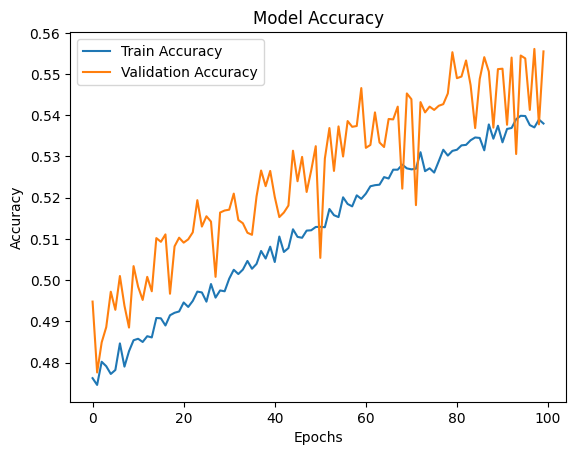

In [170]:
# Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='upper left')
plt.show()

Compiling the model: using "adam" optimizer, "CategoricalCrossentropy" loss function and "accuracy" as metrics.
The model will be trained over 10 epochs.

In [194]:
# some experimentations with different optimisers
sgd = optimizers.SGD(learning_rate=0.001)
adam = optimizers.Adam(learning_rate=0.001)
adamax = optimizers.Adamax()
lamb = optimizers.Lamb(learning_rate=0.001)

In [196]:

model.compile(optimizer=adam,
              loss='CategoricalCrossentropy',
              metrics=['accuracy'])

history = model.fit(train_images, train_y, epochs=30, 
                    validation_data=(test_images, test_y))

Epoch 1/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.6287 - loss: 1.2099 - val_accuracy: 0.6157 - val_loss: 1.2592
Epoch 2/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6325 - loss: 1.1948 - val_accuracy: 0.6270 - val_loss: 1.2191
Epoch 3/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6409 - loss: 1.1759 - val_accuracy: 0.6374 - val_loss: 1.1833
Epoch 4/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6440 - loss: 1.1640 - val_accuracy: 0.6397 - val_loss: 1.1816
Epoch 5/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6497 - loss: 1.1530 - val_accuracy: 0.6413 - val_loss: 1.1770
Epoch 6/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6536 - loss: 1.1392 - val_accuracy: 0.6516 - val_loss: 1.1550
Epoch 7/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 11ms/step - accuracy: 0.6598 - loss: 1.1306 - val_accuracy: 0.6254 - val_loss: 1.2286
Epoch 8/30
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.6604 - 